**Project Goal**
This project aims to analyze the historically disputed authorship of the Epistle to the Hebrews using computational stylometry. By comparing the vocabulary footprint of Hebrews against the known writings of Paul and Luke, I will use word frequency distributions to evaluate whose linguistic style most closely matches the unknown author.

**Data Sources & Comparisons**
To eliminate English translator bias, this analysis will rely on the original Koine Greek text sourced from the Blue Letter Bible. The specific comparisons include:
* **The Disputed Text:** The Epistle to the Hebrews.
* **Pauline Baseline:** Romans and 1 Corinthians.
* **Lukan Baseline:** The Gospel of Luke and Acts of the Apostles.

**Technical Methodology**
* **Ingestion:** Utilize the `requests` library to fetch interlinear HTML pages from the Blue Letter Bible.
* **Targeted Extraction:** Use `BeautifulSoup` to target specific HTML classes, isolating the Greek *lemmas* (root words) rather than the highly inflected raw text.
* **Custom Filtering:** Bypass standard `nltk` English stop words by implementing a custom Python dictionary of common Greek articles, conjunctions, and prepositions (e.g., καί, ὁ, ἡ, ἐν) to strip out grammatical noise.
* **Frequency Mapping:** Apply the `Counter` module to generate associative arrays of the top 50 distinctive lemmas for each corpus, ultimately calculating the overlap percentage between Hebrews and the two baseline authors.

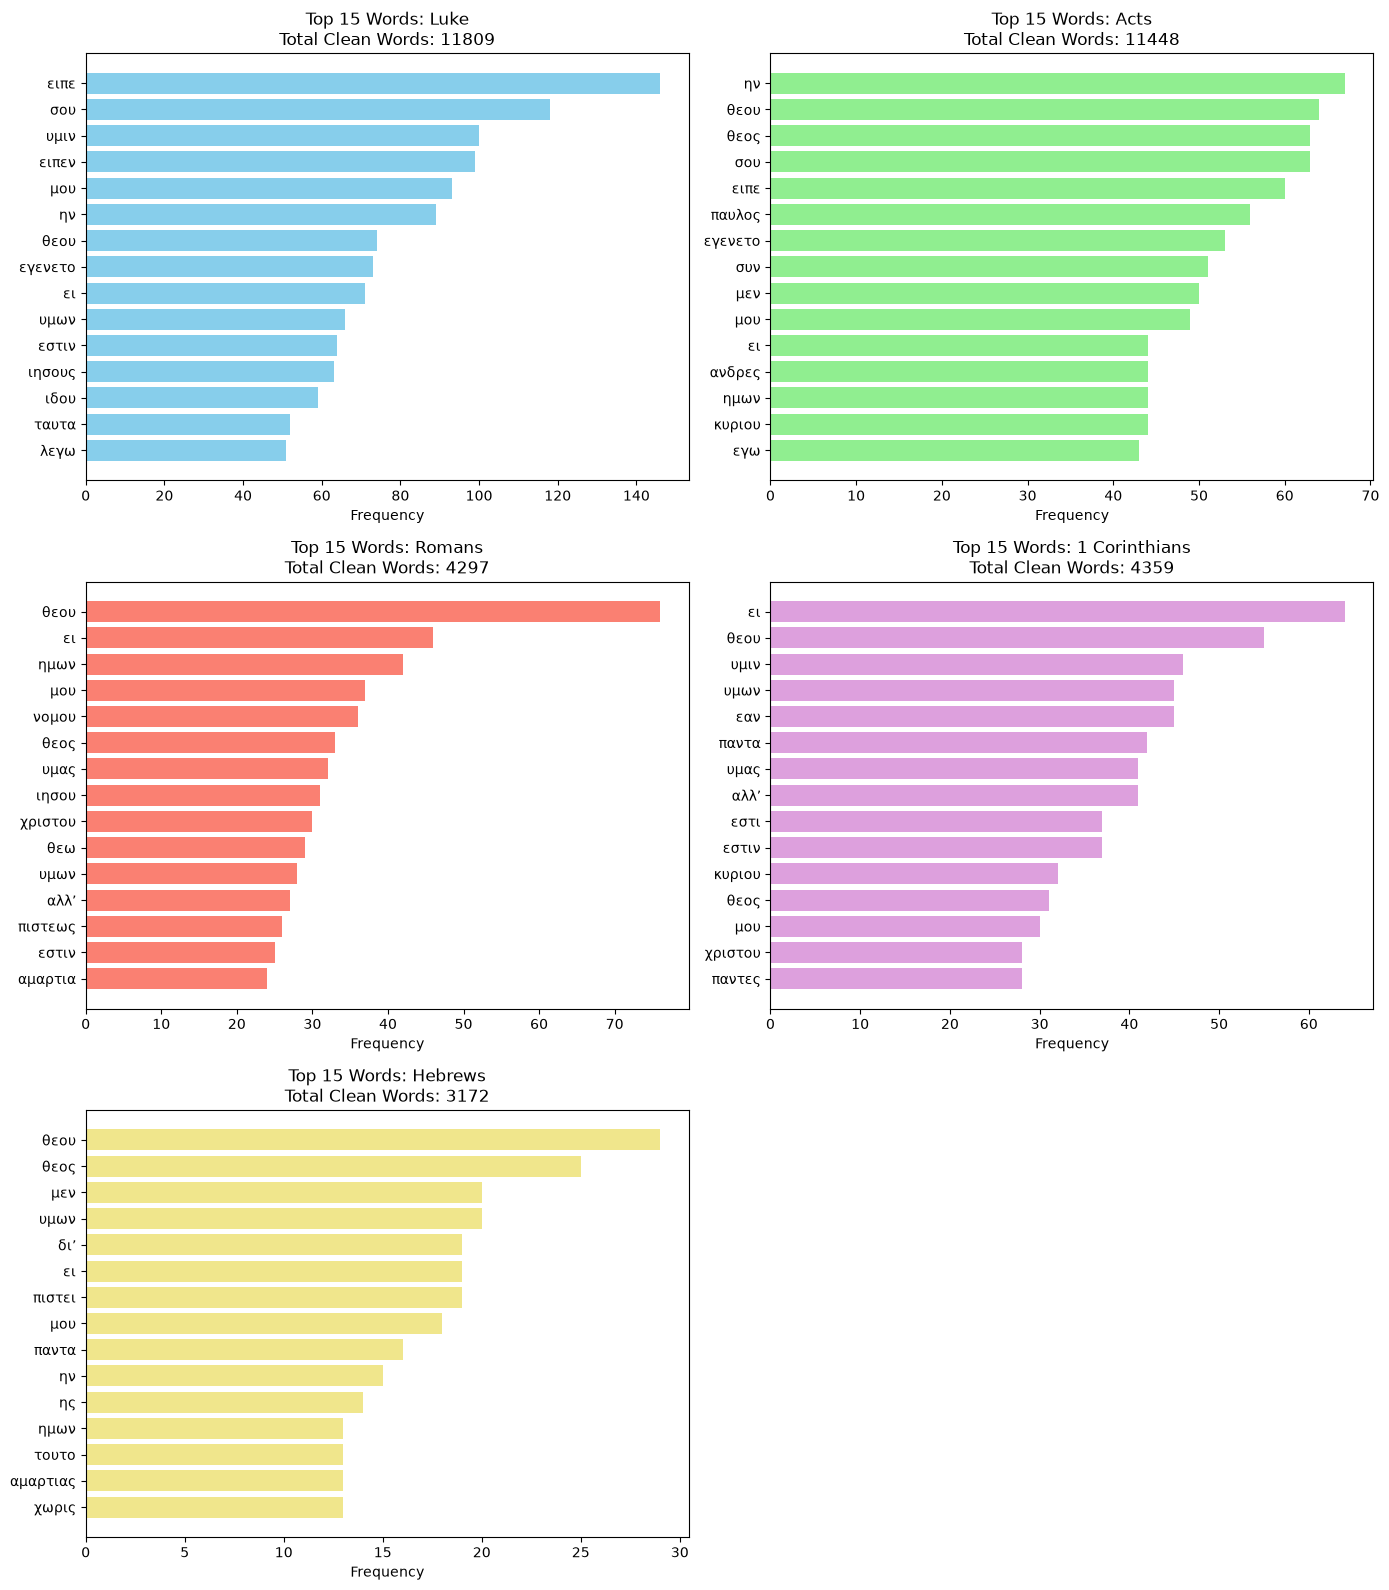

In [3]:
import requests
from bs4 import BeautifulSoup
import re
from collections import Counter
import unicodedata
import matplotlib.pyplot as plt

# 1. Define a helper function to strip accents and breathings
def strip_diacritics(text):
    return ''.join(c for c in unicodedata.normalize('NFD', text) if unicodedata.category(c) != 'Mn')

assignment_urls = {
    "Luke": "https://el.wikisource.org/wiki/Κατά_Λουκάν",
    "Acts": "https://el.wikisource.org/wiki/Πράξεις_των_Αποστόλων",
    "Romans": "https://el.wikisource.org/wiki/Προς_Ρωμαίους",
    "1 Corinthians": "https://el.wikisource.org/wiki/Προς_Κορινθίους_Α",
    "Hebrews": "https://el.wikisource.org/wiki/Προς_Εβραίους"
}

# 2. Raw stop words
raw_stop_words = [
    'καί', 'ὁ', 'ἡ', 'τό', 'οἱ', 'αἱ', 'τά', 'τοῦ', 'τῆς', 'τῶν', 
    'τῷ', 'τῇ', 'τοῖς', 'ταῖς', 'τόν', 'τήν', 'τούς', 'τάς', 'ἐν', 
    'εἰς', 'ἐκ', 'ἐξ', 'πρός', 'δέ', 'γάρ', 'ὅτι', 'μή', 'οὐ', 
    'οὐκ', 'οὐχ', 'αὐτός', 'αὐτή', 'αὐτό', 'αὐτοῦ', 'αὐτῆς', 'αὐτῶν', 
    'αὐτῷ', 'αὐτῇ', 'αὐτοῖς', 'αὐτόν', 'αὐτήν', 'αὐτούς', 'ἐπί', 
    'κατά', 'μετά', 'οὖν', 'περί', 'ἀλλά', 'ἵνα', 'τις', 'τι', 
    'ὡς', 'ἀπό', 'ὑπό', 'διά', 'γε', 'τε'
]

# 3. Normalize the stop words (lowercase + strip diacritics)
koine_stop_words = set(strip_diacritics(w.lower()) for w in raw_stop_words)

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) ComparativeTextBot/1.0'
}

def clean_html(html_content):
    soup = BeautifulSoup(html_content, 'html.parser')
    main_body = soup.find('div', class_='mw-parser-output')
    if main_body:
        return main_body.get_text(separator=' ')
    return soup.get_text(separator=' ')

def process_web_text(url):
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        return f"Failed to fetch page."
    
    raw_text = clean_html(response.text)
    clean_text = re.sub(r'[0-9a-zA-Z.,;··;:\[\]\(\)\n\r\t]', ' ', raw_text)
    
    # 4. Split text, normalize it, and strip diacritics for matching
    words = [strip_diacritics(w) for w in clean_text.lower().split()]
    filtered_words = [word for word in words if word not in koine_stop_words]
    
    word_freq = Counter(filtered_words)
    return word_freq.most_common(15), len(filtered_words)

# for book, url in assignment_urls.items():
#     print(f"\nTop 15 words in {book}:")
#     frequencies = process_web_text(url)
    
#     if isinstance(frequencies, str):
#         print(frequencies)
#     else:
#         for word, count in frequencies:
#             print(f"{word}: {count}")

# Set up a 3-row by 2-column plot grid for the 5 books
fig, axes = plt.subplots(3, 2, figsize=(14, 16))
axes = axes.flatten()

# Colors for visual distinction across subplots
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'khaki']

for idx, (book, url) in enumerate(assignment_urls.items()):
    ax = axes[idx]
    result = process_web_text(url)
    
    if result:
        freq_list, total_clean_words = result
        
        # Reversing the list [::-1] ensures the highest frequency word appears at the top
        words = [item[0] for item in freq_list][::-1]
        counts = [item[1] for item in freq_list][::-1]
        
        ax.barh(words, counts, color=colors[idx])
        ax.set_title(f'Top 15 Words: {book}\nTotal Clean Words: {total_clean_words}')
        ax.set_xlabel('Frequency')

# Hide the unused 6th subplot frame
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()